# Heart Disease Prediction – Machine Learning Mini Project

**Algorithms:** K-Nearest Neighbors (KNN), Decision Tree, Logistic Regression

**Dataset:** UCI Heart Disease – Cleveland dataset (`heart_disease_dataset.csv`)

**Objective:** Classify whether heart disease is present (1) or absent (0) using 13 clinical attributes.

Run the cells from top to bottom. The dataset is downloaded from the UCI Machine Learning Repository and saved as `heart_disease_dataset.csv` in the notebook folder.

> Educational machine-learning exercise only. This model is not a medical diagnostic tool and must not be used for clinical decisions.


## 1. Import required libraries

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


## 2. Load the dataset

In [26]:
# Download the original Cleveland heart disease dataset from UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

data = pd.read_csv(url, names=columns, na_values="?")

# Convert the original target (0 to 4) into binary classification:
# 0 = no heart disease; 1 = presence of heart disease
data["target"] = (data["num"] > 0).astype(int)
data = data.drop(columns=["num"])

# Save a local copy so it can also be uploaded to GitHub
data.to_csv("heart_disease_dataset.csv", index=False)

# Display the first five rows
print(data.head())

# Display dataset information
print("\\nDataset shape:", data.shape)
print("\\nMissing values:")
print(data.isnull().sum())
print("\\nTarget distribution:")
print(data["target"].value_counts())


    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       1  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  
\nDataset shape: (303, 14)
\nMissing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
\nTarget distribution:
target
0    164
1    139
Name: count, dtype: int64


## 3. Separate input and output

In [27]:
# Input features
X = data.drop("target", axis=1)

# Output label
y = data["target"]

print("Input features:")
print(X.head())
print("\\nOutput labels:")
print(y.head())


Input features:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  
0    3.0  0.0   6.0  
1    2.0  3.0   3.0  
2    2.0  2.0   7.0  
3    3.0  0.0   3.0  
4    1.0  0.0   3.0  
\nOutput labels:
0    0
1    1
2    1
3    0
4    0
Name: target, dtype: int64


## 4. Split the dataset

In [28]:
# 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (242, 13)
Testing data: (61, 13)


## 5. Feature scaling (for KNN and Logistic Regression)

In [29]:
# Impute missing feature values using the median, then scale the features.
# Fit preprocessing only on training data to avoid data leakage.
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Training data after preprocessing:", X_train_scaled.shape)
print("Testing data after preprocessing:", X_test_scaled.shape)


## 6. Apply K-Nearest Neighbors (KNN)

In [30]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)
knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")


KNN Accuracy: 88.52 %


## 7. Apply Decision Tree

In [31]:
decision_tree = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(random_state=42)
)
decision_tree.fit(X_train, y_train)

tree_pred = decision_tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)

print("Decision Tree Accuracy:", round(tree_accuracy * 100, 2), "%")


Decision Tree Accuracy: 73.77 %


## 8. Apply Logistic Regression

In [32]:
logistic = LogisticRegression(max_iter=1000)
logistic.fit(X_train_scaled, y_train)

logistic_pred = logistic.predict(X_test_scaled)
logistic_accuracy = accuracy_score(y_test, logistic_pred)

print("Logistic Regression Accuracy:", round(logistic_accuracy * 100, 2), "%")


Logistic Regression Accuracy: 86.89 %


## 9. Compare the algorithms

          Algorithm  Accuracy (%)
                KNN     88.524590
      Decision Tree     73.770492
Logistic Regression     86.885246


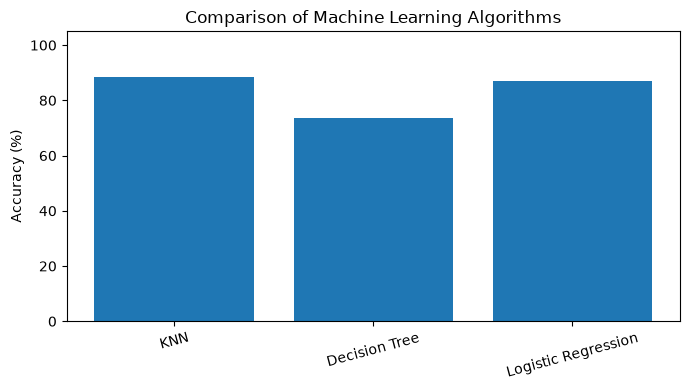

\nBest algorithm: KNN
Best accuracy: 88.52 %


In [33]:
results = pd.DataFrame({
    "Algorithm": ["KNN", "Decision Tree", "Logistic Regression"],
    "Accuracy (%)": [
        knn_accuracy * 100,
        tree_accuracy * 100,
        logistic_accuracy * 100
    ]
})

print(results.to_string(index=False))

# Plot accuracy comparison
plt.figure(figsize=(7, 4))
plt.bar(results["Algorithm"], results["Accuracy (%)"])
plt.ylabel("Accuracy (%)")
plt.title("Comparison of Machine Learning Algorithms")
plt.ylim(0, 105)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

best = results.loc[results["Accuracy (%)"].idxmax()]
print("\\nBest algorithm:", best["Algorithm"])
print("Best accuracy:", round(best["Accuracy (%)"], 2), "%")


## 10. Classification report (example: KNN)

In [34]:
print(classification_report(
    y_test, knn_pred,
    target_names=["No heart disease", "Heart disease"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, knn_pred))


                  precision    recall  f1-score   support

No heart disease       1.00      0.79      0.88        33
   Heart disease       0.80      1.00      0.89        28

        accuracy                           0.89        61
       macro avg       0.90      0.89      0.89        61
    weighted avg       0.91      0.89      0.88        61

Confusion matrix:
[[26  7]
 [ 0 28]]


## 11. Conclusion

In this project, the UCI Cleveland Heart Disease dataset was used to build three binary classification models: K-Nearest Neighbors (KNN), Decision Tree and Logistic Regression. The original target values were converted into two classes: 0 (no disease) and 1 (presence of disease). Missing feature values were imputed, the data was split into training and testing sets, and feature scaling was applied for KNN and Logistic Regression. The accuracy scores were compared to evaluate model performance. The algorithm with the highest test accuracy performed best for this experiment.

**Note:** This is an educational exercise using a small historical dataset. Model predictions are not medical advice or a substitute for professional diagnosis.
